# Customer Experience and Order-placement Risk

Customer reviews reflect more than whether an order arrived on time. This exploratory analysis examines review coverage, order characteristics, and fulfillment outcomes to establish the business context for identifying customer-experience risk at order placement.

The analysis uses the consolidated item baseline and summarizes results at one observation per order. It includes orders represented in that baseline regardless of eventual status; orders without items are documented in preprocessing. Missing reviews remain unknown outcomes. Delivery and seller-deadline outcomes provide retrospective context and are unavailable when an order is placed.

The narrative moves from population and review coverage to historical context, placement-time characteristics, and delivery experience. These findings establish the context for evaluating customer-experience risk using information available at order placement.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

## Order population and review context — Asher

## Population and Review Coverage

The baseline describes marketplace activity across customers, sellers, and products. Reviewed orders form the population for comparisons involving ratings; unreviewed orders remain in coverage summaries.

In [5]:
# Resolve data files using the GitHub repository folder structure.
from pathlib import Path

def resolve_data_file(filename, data_type="raw"):
    data_path = Path("..") / "01_data" / data_type / filename
    if not data_path.is_file():
        raise FileNotFoundError(
            f"Could not find {filename} at {data_path}. "
            "Run this notebook from the repository's 03_final folder."
        )
    return data_path


In [6]:
olist_df = pd.read_csv(
    str(resolve_data_file("olist_order_item_baseline.csv", "preprocessed")),
    parse_dates=["order_purchase_timestamp", "order_delivered_carrier_date",
                 "order_delivered_customer_date", "order_estimated_delivery_date"],
)

order_info = olist_df.drop_duplicates("order_id").copy()
order_info["reviewed"] = order_info["last_review_score"].notna()
order_info["low_review"] = np.where(
    order_info["reviewed"], order_info["last_review_score"].le(2), np.nan
)

In [7]:
population_summary = pd.DataFrame({
    "Count": {
        "Orders": olist_df["order_id"].nunique(),
        "Customers": olist_df["customer_unique_id"].nunique(),
        "Sellers": olist_df["seller_id"].nunique(),
        "Products": olist_df["product_id"].nunique(),
    }
})
review_coverage = pd.DataFrame({
    "Orders": {
        "Reviewed": int(order_info["reviewed"].sum()),
        "No observed review": int((~order_info["reviewed"]).sum()),
    }
})
review_coverage["Share of all orders"] = review_coverage["Orders"] / len(order_info)
display(population_summary.style.format("{:,.0f}"))
display(review_coverage.style.format({
    "Orders": "{:,.0f}", "Share of all orders": "{:.1%}",
}))

,Count
Orders,"98,666"
Customers,"95,420"
Sellers,"3,095"
Products,"32,951"


,Orders,Share of all orders
Reviewed,"97,917",99.2%
No observed review,749,0.8%


In [8]:
review_distribution = (
    olist_df.groupby("order_id")["last_review_score"]
    .first()
    .value_counts()
    .sort_index()
    .to_frame("orders")
)

review_distribution["percent"] = (
    review_distribution["orders"]
    / review_distribution["orders"].sum()
)

display(review_distribution.rename(
    columns={"orders": "Reviewed orders", "percent": "Share of reviewed orders"}
).rename_axis("Review score").style.format({
    "Reviewed orders": "{:,.0f}", "Share of reviewed orders": "{:.1%}",
}).format_index("{:.0f}"))

,Reviewed orders,Share of reviewed orders
Review score,,
1,"10,824",11.1%
2,"3,069",3.1%
3,"8,080",8.3%
4,"19,006",19.4%
5,"56,938",58.1%


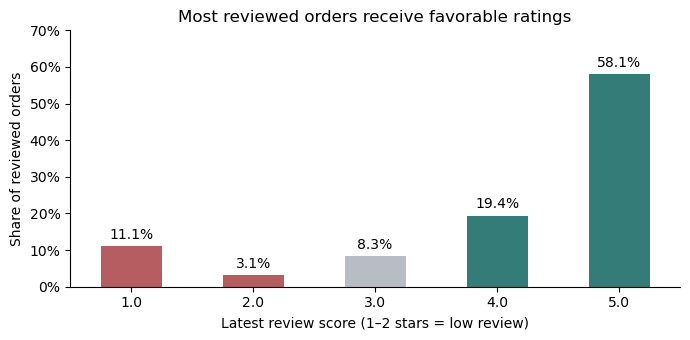

In [9]:
# Highlight the low-review target within the full rating distribution.
ax = review_distribution["percent"].plot.bar(
    color=["#B55D60", "#B55D60", "#B7BDC5", "#347C78", "#347C78"],
    figsize=(7, 3.5), rot=0,
)
ax.bar_label(ax.containers[0], labels=[
    f"{share:.1%}" for share in review_distribution["percent"]
], padding=3)
ax.set_title("Most reviewed orders receive favorable ratings")
ax.set_xlabel("Latest review score (1–2 stars = low review)")
ax.set_ylabel("Share of reviewed orders")
ax.set_ylim(0, 0.7)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


Of the 98,666 orders in the item baseline, 97,917 have an observed review. Low ratings of 1–2 stars account for 13,893 orders, or 14.2% of reviewed orders. The remaining reviewed orders receive 3–5 stars. This imbalance makes the proportion of low reviews an important reference point for later comparisons.

### Review Coverage by Recorded Order Status

Recorded status helps describe review availability, but it does not determine inclusion in the analysis. Processing and shipped statuses are source snapshots rather than proof of terminal outcomes. Rates below use reviewed orders for low-review prevalence and all orders within each status for review coverage.

In [12]:
status_coverage = order_info.groupby("order_status").agg(
    total_orders=("order_id", "size"),
    reviewed_orders=("reviewed", "sum"),
    low_reviews=("low_review", "sum"),
    low_review_rate=("low_review", "mean"),
)
status_coverage["no_review_orders"] = (
    status_coverage["total_orders"] - status_coverage["reviewed_orders"]
)
status_coverage["review_rate"] = (
    status_coverage["reviewed_orders"] / status_coverage["total_orders"]
)
display(status_coverage.rename(columns={
    "total_orders": "Total orders", "reviewed_orders": "Reviewed orders",
    "low_reviews": "Low reviews", "low_review_rate": "Low-review rate",
    "no_review_orders": "No review", "review_rate": "Review coverage",
}).rename_axis("Recorded status").style.format({
    "Total orders": "{:,.0f}", "Reviewed orders": "{:,.0f}",
    "Low reviews": "{:,.0f}", "No review": "{:,.0f}",
    "Low-review rate": "{:.1%}", "Review coverage": "{:.1%}",
}))

,Total orders,Reviewed orders,Low reviews,Low-review rate,No review,Review coverage
Recorded status,,,,,,
approved,2,2,1,50.0%,0,100.0%
canceled,461,444,369,83.1%,17,96.3%
delivered,"96,478","95,832","12,273",12.8%,646,99.3%
invoiced,312,307,254,82.7%,5,98.4%
processing,301,295,274,92.9%,6,98.0%
shipped,"1,106","1,031",717,69.5%,75,93.2%
unavailable,6,6,5,83.3%,0,100.0%


### Review Outcome Definition

The latest answered review defines the low-review outcome. The following sensitivity check compares that choice with first-review and average-review classifications. The results describe label agreement, rather than an additional prediction target.

In [14]:
reviewed_orders = order_info.loc[order_info["reviewed"]]
latest_low = reviewed_orders["last_review_score"].le(2)
review_checks = []
for name, column in [("First vs latest", "first_review_score"),
                     ("Mean vs latest", "avg_review_score")]:
    changed = reviewed_orders[column].le(2).ne(latest_low)
    multiple = reviewed_orders["review_count"].gt(1)
    review_checks.append(
        {"comparison": name, "changed_orders": changed.sum(),
         "share_of_reviewed": changed.mean(),
         "share_of_multiple_reviews": changed[multiple].mean()}
    )
display(pd.DataFrame(review_checks).set_index("comparison").rename(columns={
    "changed_orders": "Changed labels",
    "share_of_reviewed": "Share of reviewed orders",
    "share_of_multiple_reviews": "Share of multiple-review orders",
}).style.format({
    "Changed labels": "{:,.0f}", "Share of reviewed orders": "{:.3%}",
    "Share of multiple-review orders": "{:.1%}",
}))

,Changed labels,Share of reviewed orders,Share of multiple-review orders
comparison,,,
First vs latest,95,0.097%,17.5%
Mean vs latest,58,0.059%,10.7%


First versus latest review changes 95 labels (0.097% of reviewed orders); average versus latest changes 58 (0.059%). These small differences support retaining the existing latest-review definition. Detailed review chronology and pre-purchase timestamp anomalies are documented in preprocessing.

## Historical Activity and Calendar Context

Historical volume and review prevalence describe the population available for modeling. The figure separates marketplace activity from the rate of low reviews among reviewed orders. Months with fewer than 100 reviews are omitted from the prevalence line because their rates are unstable.

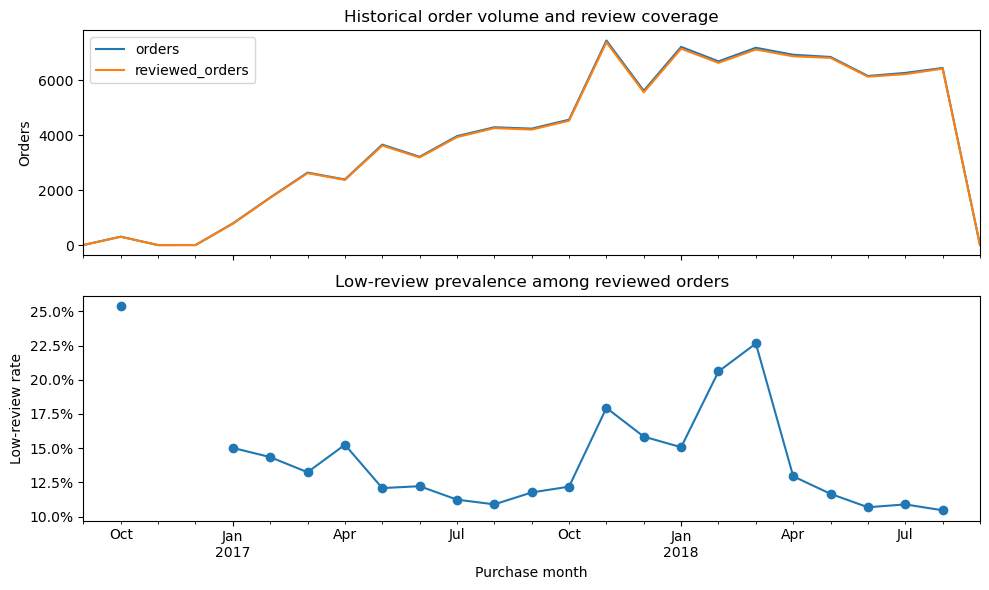

In [17]:
monthly = order_info.set_index("order_purchase_timestamp").resample("MS").agg(
    orders=("order_id", "size"),
    reviewed_orders=("reviewed", "sum"),
    low_review_rate=("low_review", "mean"),
)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
monthly[["orders", "reviewed_orders"]].plot(ax=axes[0])
axes[0].set_ylabel("Orders")
monthly["low_review_rate"].where(
    monthly["reviewed_orders"].ge(100)
).plot(ax=axes[1], marker="o")
axes[1].set_ylabel("Low-review rate")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_title("Historical order volume and review coverage")
axes[1].set_title("Low-review prevalence among reviewed orders")
axes[1].set_xlabel("Purchase month")
plt.tight_layout()
plt.show()

### Purchase Month-year Diagnostic

The detailed table retains all months with reviewed orders, including sparse periods omitted from the figure. Its reviewed-order population follows the modeling aggregation rules. Comparing the same months across years provides context for calendar predictors without assuming that a historical pattern recurs each year.

In [19]:
# Reconstruct the reviewed order population using the modeling aggregation rules.
eda_reviewed_orders = (
    olist_df.groupby("order_id")
    .agg(
        order_purchase_timestamp=("order_purchase_timestamp", "first"),
        order_estimated_delivery_date=("order_estimated_delivery_date", "first"),
        last_review_score=("last_review_score", "first"),
    )
    .reset_index()
    .dropna(subset=["last_review_score"])
    .reset_index(drop=True)
)
eda_reviewed_orders["low_review_2"] = (
    eda_reviewed_orders["last_review_score"].le(2).astype(int)
)

# Compare prevalence for each observed year-month at order grain.
month_year = (
    eda_reviewed_orders.set_index("order_purchase_timestamp")
    .resample("MS")["low_review_2"]
    .agg(reviewed_orders="size", low_review_rate="mean")
)
month_year = month_year.loc[month_year["reviewed_orders"].gt(0)]
display(month_year.rename(columns={
    "reviewed_orders": "Reviewed orders", "low_review_rate": "Low-review rate",
}).rename_axis("Purchase month").style.format({
    "Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}",
}).format_index(lambda date: date.strftime("%Y-%m")))

,Reviewed orders,Low-review rate
Purchase month,,
2016-09,3,100.0%
2016-10,303,25.4%
2016-12,1,0.0%
2017-01,779,15.0%
2017-02,"1,722",14.3%
2017-03,"2,621",13.2%
2017-04,"2,374",15.2%
2017-05,"3,626",12.1%
2017-06,"3,192",12.2%


### Monthly Review Prevalence Across Years

Comparing the same calendar months highlights differences between 2017 and 2018. The figure shows months with at least 100 reviewed orders, consistent with the historical prevalence plot; missing months are not filled or extrapolated. The detailed table above retains every observed month.

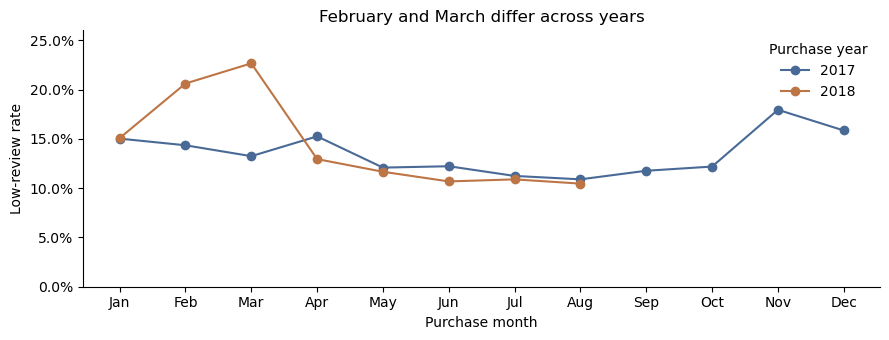

In [21]:
monthly_comparison = month_year.loc[
    month_year.index.year.isin([2017, 2018])
    & month_year["reviewed_orders"].ge(100)
].copy()
monthly_comparison["Year"] = monthly_comparison.index.year
monthly_comparison["Month"] = monthly_comparison.index.month
monthly_comparison = monthly_comparison.pivot(
    index="Month", columns="Year", values="low_review_rate"
).reindex(range(1, 13))

ax = monthly_comparison.plot(
    marker="o", color=["#496A96", "#BE7545"], figsize=(9, 3.5)
)
ax.set_title("February and March differ across years")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Low-review rate")
ax.set_xticks(range(1, 13))
ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
])
ax.set_ylim(0, 0.26)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(title="Purchase year", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

February and March have higher low-review prevalence in 2018 (20.6% and 22.7%) than in 2017 (14.3% and 13.2%). July and August are more consistent across the two years. These differences support interpreting calendar predictors as historical context rather than established seasonality, and motivate the chronological sensitivity evaluation in modeling. They do not identify a disruption or separate timing from changes in order composition.

## Repeat Purchasing and Analytical Focus

Repeat purchasing provides context for the choice of an order-risk objective. The distribution counts unique orders per customer; timing summaries describe the first observed order and its next observed purchase.

In [24]:
customer_orders = (
    olist_df[["customer_unique_id", "order_id"]]
    .drop_duplicates()
    .groupby("customer_unique_id")
    .size()
)

repeat_customer_rate = (customer_orders > 1).mean()
customer_frequency = customer_orders.value_counts().sort_index().to_frame("Customers")
customer_frequency["Share of customers"] = (
    customer_frequency["Customers"] / len(customer_orders)
)
display(customer_frequency.rename_axis("Observed orders per customer").style.format({
    "Customers": "{:,.0f}", "Share of customers": "{:.2%}",
}))

,Customers,Share of customers
Observed orders per customer,,
1,"92,507",96.95%
2,"2,673",2.80%
3,192,0.20%
4,29,0.03%
5,9,0.01%
6,5,0.01%
7,3,0.00%
9,1,0.00%
16,1,0.00%


Only 3.05% of customers have multiple observed orders. Sparse repeat history supports the order-level customer-experience focus; it does not establish long-term retention rates.

## Marketplace categories — Bereket

Product mix provides context for order composition and merchandise value. The following existing category summaries describe item activity, not low-review risk. Category order counts can overlap when an order contains multiple categories.

In [27]:
# Load source tables required by the retained category and seller blocks.
items = pd.read_csv(str(resolve_data_file("olist_order_items_dataset.csv", "raw")))
products = pd.read_csv(str(resolve_data_file("olist_products_dataset.csv", "raw")))
category_translation = pd.read_csv(
    str(resolve_data_file("product_category_name_translation.csv", "raw"))
)
orders = pd.read_csv(str(resolve_data_file("olist_orders_dataset.csv", "raw")))
reviews = pd.read_csv(str(resolve_data_file("olist_order_reviews_dataset.csv", "raw")))
sellers = pd.read_csv(str(resolve_data_file("olist_sellers_dataset.csv", "raw")))
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])


In [28]:
products_en = products.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

product_items = items.merge(
    products_en,
    on="product_id",
    how="left"
)

category_summary = (
    product_items.groupby("product_category_name_english", dropna=False)
    .agg(
        item_lines=("order_item_id", "count"),
        orders=("order_id", "nunique"),
        sellers=("seller_id", "nunique"),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        avg_price=("price", "mean"),
        avg_weight_g=("product_weight_g", "mean")
    )
    .sort_values("merchandise_value", ascending=False)
)

category_summary.head(20)

,item_lines,orders,sellers,merchandise_value,freight_value,avg_price,avg_weight_g
product_category_name_english,,,,,,,
health_beauty,9670,8836,492,1258681.34,182566.73,130.163531,1048.766391
watches_gifts,5991,5624,101,1205005.68,100535.93,201.135984,580.976632
bed_bath_table,11115,9417,196,1036988.68,204693.04,93.296327,2116.753396
sports_leisure,8641,7720,481,988048.97,168607.51,114.344285,1743.061567
computers_accessories,7827,6689,287,911954.32,147318.08,116.513903,902.509135
furniture_decor,8334,6449,370,729762.49,172749.30,87.564494,2653.128870
cool_stuff,3796,3632,267,635290.85,84039.10,167.357969,2548.971286
housewares,6964,5884,468,632248.66,146149.11,90.788148,3214.587881
auto,4235,3897,383,592720.11,92664.21,139.957523,2594.148288


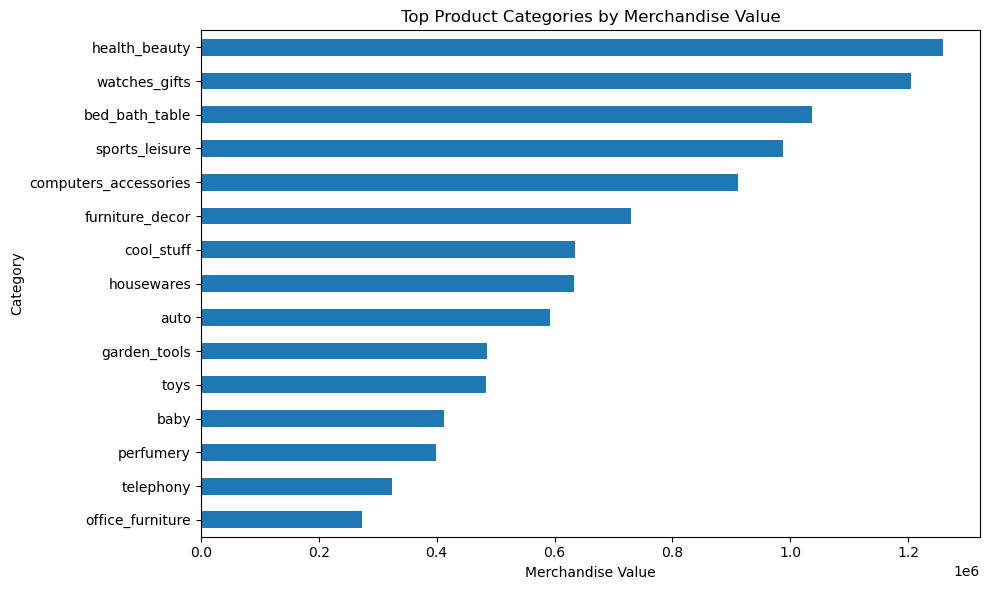

In [29]:
top_cat_plot = category_summary.head(15).sort_values("merchandise_value")
plt.figure(figsize=(10, 6))
top_cat_plot["merchandise_value"].plot(kind="barh")
plt.title("Top Product Categories by Merchandise Value")
plt.xlabel("Merchandise Value")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

## Seller activity and marketplace concentration — Bereket

Seller transaction depth and merchandise-sales concentration provide context for seller-support prioritization. For consistency with the order-level analysis, the seller summaries below classify lateness by promised **calendar date**, select the latest review by **answer timestamp**, and calculate review rates **among reviewed seller-orders only**. Seller-order reviews are associated with each seller appearing on an order and cannot establish individual seller responsibility for the rating.

### Delivery timing definition

A delivery is late only if the actual **calendar date** is after the estimated delivery calendar date. Orders without both dates have an unknown late-delivery status. The separate continuous `delivery_vs_estimate_days` measure retains its original timestamp-based definition.

In [32]:
orders_dt = orders.copy()

date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_cols:
    orders_dt[col] = pd.to_datetime(orders_dt[col], errors="coerce")

orders_dt["purchase_to_approval_hours"] = (
    orders_dt["order_approved_at"] - orders_dt["order_purchase_timestamp"]
).dt.total_seconds() / 3600

orders_dt["purchase_to_carrier_days"] = (
    orders_dt["order_delivered_carrier_date"] - orders_dt["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders_dt["purchase_to_delivery_days"] = (
    orders_dt["order_delivered_customer_date"] - orders_dt["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders_dt["delivery_vs_estimate_days"] = (
    orders_dt["order_delivered_customer_date"] - orders_dt["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

orders_dt["promised_window_days"] = (
    orders_dt["order_estimated_delivery_date"] - orders_dt["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders_dt["late_delivery"] = np.where(
    orders_dt["order_delivered_customer_date"].notna()
    & orders_dt["order_estimated_delivery_date"].notna(),
    (orders_dt["order_delivered_customer_date"].dt.normalize()
     > orders_dt["order_estimated_delivery_date"].dt.normalize()),
    np.nan
)

orders_dt["purchase_year_month"] = orders_dt["order_purchase_timestamp"].dt.to_period("M").astype(str)
orders_dt["purchase_weekday"] = orders_dt["order_purchase_timestamp"].dt.day_name()
orders_dt["purchase_hour"] = orders_dt["order_purchase_timestamp"].dt.hour

orders_dt[[
    "purchase_to_approval_hours",
    "purchase_to_carrier_days",
    "purchase_to_delivery_days",
    "delivery_vs_estimate_days",
    "promised_window_days"
]].describe()

,purchase_to_approval_hours,purchase_to_carrier_days,purchase_to_delivery_days,delivery_vs_estimate_days,promised_window_days
count,99281.000000,97658.000000,96476.000000,96476.000000,99441.000000
mean,10.419094,3.234050,12.558702,-11.179120,23.767650
std,26.038004,3.611996,9.546530,10.186113,8.832371
min,0.000000,-171.212419,0.533414,-146.016123,1.648993
25%,0.215000,1.128967,6.766403,-16.244384,18.331690
50%,0.343333,2.204676,10.217755,-11.948941,23.240370
75%,14.580833,4.071777,15.720327,-6.390000,28.424861
max,4509.180556,125.775521,209.628611,188.975081,155.135463


In [33]:
reviews_dt = reviews.copy()
reviews_dt["review_creation_date"] = pd.to_datetime(
    reviews_dt["review_creation_date"], errors="coerce"
)
reviews_dt["review_answer_timestamp"] = pd.to_datetime(
    reviews_dt["review_answer_timestamp"], errors="coerce"
)

review_count_per_order = reviews_dt.groupby("order_id").size().rename("review_record_count")
review_count_per_order.value_counts().sort_index()

review_record_count
1    98126
2      543
3        4
Name: count, dtype: int64

### Latest-review selection

Review records are ordered by `review_answer_timestamp` to align the seller-level descriptive analysis with the order-level target definition in preprocessing. If several reviews exist for one order, the last answered review supplies `last_review_score`.

In [35]:
review_sequence = reviews_dt.sort_values(
    ["order_id", "review_answer_timestamp"]
).copy()

review_sequence["review_sequence_number"] = (
    review_sequence.groupby("order_id").cumcount() + 1
)

review_change_summary = (
    review_sequence.groupby("order_id")
    .agg(
        review_count=("review_score", "size"),
        first_review_score=("review_score", "first"),
        last_review_score=("review_score", "last"),
        mean_review_score=("review_score", "mean"),
        min_review_score=("review_score", "min"),
        max_review_score=("review_score", "max"),
        first_review_date=("review_creation_date", "first"),
        last_review_date=("review_creation_date", "last")
    )
    .reset_index()
)

review_change_summary["score_change"] = (
    review_change_summary["last_review_score"] -
    review_change_summary["first_review_score"]
)

review_change_summary["score_change_direction"] = np.select(
    [
        review_change_summary["score_change"] > 0,
        review_change_summary["score_change"] < 0,
        review_change_summary["score_change"] == 0,
    ],
    ["Improved", "Declined", "No change"],
    default="Unknown"
)

review_change_summary.loc[
    review_change_summary["review_count"] > 1,
    "score_change_direction"
].value_counts()

score_change_direction
No change    346
Declined     113
Improved      88
Name: count, dtype: int64

In [36]:
seller_order = (
    items.groupby(["seller_id", "order_id"])
    .agg(
        seller_item_lines=("order_item_id", "count"),
        seller_unique_products=("product_id", "nunique"),
        seller_merchandise_value=("price", "sum"),
        seller_freight_value=("freight_value", "sum"),
        seller_first_shipping_limit=("shipping_limit_date", "min"),
        seller_last_shipping_limit=("shipping_limit_date", "max")
    )
    .reset_index()
)

seller_order = seller_order.merge(
    orders_dt[[
        "order_id", "order_status", "order_purchase_timestamp",
        "order_delivered_carrier_date", "order_delivered_customer_date",
        "order_estimated_delivery_date", "purchase_to_delivery_days",
        "delivery_vs_estimate_days", "late_delivery"
    ]],
    on="order_id",
    how="left"
)

seller_order = seller_order.merge(
    review_change_summary[[
        "order_id", "mean_review_score", "last_review_score",
        "review_count", "score_change"
    ]],
    on="order_id",
    how="left"
)

seller_order["seller_deadline_miss"] = np.where(
    seller_order["order_delivered_carrier_date"].notna() &
    seller_order["seller_last_shipping_limit"].notna(),
    seller_order["order_delivered_carrier_date"] >
    seller_order["seller_last_shipping_limit"],
    np.nan
)

seller_order["seller_shipping_delay_days"] = (
    seller_order["order_delivered_carrier_date"] -
    seller_order["seller_last_shipping_limit"]
).dt.total_seconds() / 86400

print("Seller-order rows:", len(seller_order))
print("Unique sellers:", seller_order["seller_id"].nunique())
print("Unique orders:", seller_order["order_id"].nunique())
seller_order.head()

Seller-order rows: 100010
Unique sellers: 3095
Unique orders: 98666


,seller_id,order_id,seller_item_lines,seller_unique_products,seller_merchandise_value,seller_freight_value,seller_first_shipping_limit,seller_last_shipping_limit,order_status,order_purchase_timestamp,...,order_estimated_delivery_date,purchase_to_delivery_days,delivery_vs_estimate_days,late_delivery,mean_review_score,last_review_score,review_count,score_change,seller_deadline_miss,seller_shipping_delay_days
0,0015a82c2db000af6aaaf3ae2ecb0532,7f39ba4c9052be115350065d07583cac,1,1,895.0,21.02,2017-10-24 23:56:20,2017-10-24 23:56:20,delivered,2017-10-18 08:16:34,...,2017-11-09,9.353831,-12.301331,0.0,1.0,1.0,1.0,0.0,0.0,-4.393970
1,0015a82c2db000af6aaaf3ae2ecb0532,9dc8d1a6f16f1b89874c29c9d8d30447,1,1,895.0,21.02,2017-10-18 14:49:22,2017-10-18 14:49:22,delivered,2017-10-12 13:33:22,...,2017-11-06,12.280810,-12.154352,0.0,5.0,5.0,1.0,0.0,0.0,-0.962963
2,0015a82c2db000af6aaaf3ae2ecb0532,d455a8cb295653b55abda06d434ab492,1,1,895.0,21.02,2017-10-12 22:24:16,2017-10-12 22:24:16,delivered,2017-09-26 22:17:05,...,2017-10-30,10.747014,-22.324456,0.0,5.0,5.0,1.0,0.0,0.0,-13.271678
3,001cca7ae9ae17fb1caed9dfb1094831,006e43460a55bc60c0a437521e426529,1,1,99.0,43.06,2017-05-17 01:30:22,2017-05-17 01:30:22,delivered,2017-05-11 00:24:35,...,2017-06-02,8.393542,-13.589387,0.0,5.0,5.0,1.0,0.0,0.0,-4.544329
4,001cca7ae9ae17fb1caed9dfb1094831,00dfb074b5c910fbd08e04691c4b712f,1,1,99.5,35.07,2017-06-19 19:55:19,2017-06-19 19:55:19,delivered,2017-06-08 19:43:35,...,2017-07-10,6.555833,-24.622234,0.0,5.0,5.0,1.0,0.0,0.0,-10.196273


### Seller review-rate denominators

Low-review and five-star rates use **only seller-orders with an observed review score**. Missing reviews are not treated as favorable ratings. Sellers with no reviewed orders have undefined (missing) review rates. Each order's review is attributed descriptively to all participating sellers; this does not identify which seller caused the review.

In [38]:
seller_profile = (
    seller_order.groupby("seller_id")
    .agg(
        orders=("order_id", "nunique"),
        item_lines=("seller_item_lines", "sum"),
        sales_value=("seller_merchandise_value", "sum"),
        freight_value=("seller_freight_value", "sum"),
        avg_order_value=("seller_merchandise_value", "mean"),
        avg_review=("mean_review_score", "mean"),
        median_review=("mean_review_score", "median"),
        low_review_rate=("last_review_score", lambda x: x.dropna().le(2).mean()),
        five_star_rate=("last_review_score", lambda x: x.dropna().eq(5).mean()),
        late_delivery_rate=("late_delivery", "mean"),
        seller_deadline_miss_rate=("seller_deadline_miss", "mean"),
        avg_delivery_days=("purchase_to_delivery_days", "mean"),
        avg_delivery_vs_estimate=("delivery_vs_estimate_days", "mean"),
        first_order=("order_purchase_timestamp", "min"),
        last_order=("order_purchase_timestamp", "max")
    )
    .reset_index()
)

seller_profile["active_span_days"] = (
    seller_profile["last_order"] - seller_profile["first_order"]
).dt.days

seller_profile = seller_profile.merge(sellers, on="seller_id", how="left")
seller_profile.describe(include="all").T.head(30)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
seller_id,3095,3095,0015a82c2db000af6aaaf3ae2ecb0532,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
orders,3095.0,NaN,NaN,NaN,32.313409,1.0,2.0,6.0,21.5,1854.0,105.139763
item_lines,3095.0,NaN,NaN,NaN,36.397415,1.0,2.0,8.0,24.0,2033.0,119.193461
sales_value,3095.0,NaN,NaN,NaN,4391.484233,3.5,208.85,821.48,3280.83,229472.63,13921.997192
freight_value,3095.0,NaN,NaN,NaN,727.595974,6.66,46.17,155.52,558.17,51612.55,2327.157672
avg_order_value,3095.0,NaN,NaN,NaN,194.653787,3.5,60.124693,105.87,189.970833,6729.0,346.490015
avg_review,3090.0,NaN,NaN,NaN,3.998437,1.0,3.777778,4.184699,4.6,5.0,0.955809
median_review,3090.0,NaN,NaN,NaN,4.350971,1.0,4.0,5.0,5.0,5.0,1.114681
low_review_rate,3090.0,NaN,NaN,NaN,0.176948,0.0,0.0,0.1,0.214286,1.0,0.253815
five_star_rate,3090.0,NaN,NaN,NaN,0.57331,0.0,0.450176,0.590909,0.75,1.0,0.29624


### Seller transaction depth

Order counts describe the observed history per seller. These full-history thresholds are descriptive and do not reproduce the model's five-orders-in-180-days eligibility rule.

The observed marketplace includes 3,095 sellers, with a median of six orders per seller. Of these, 1,794 have at least five orders across the full dataset; the number eligible at a particular scoring date depends on its historical window.

In [40]:
seller_depth = pd.Series({
    "total_sellers": seller_profile["seller_id"].nunique(),
    "sellers_2plus_orders": int((seller_profile["orders"] >= 2).sum()),
    "sellers_5plus_orders": int((seller_profile["orders"] >= 5).sum()),
    "sellers_10plus_orders": int((seller_profile["orders"] >= 10).sum()),
    "sellers_25plus_orders": int((seller_profile["orders"] >= 25).sum()),
    "median_orders_per_seller": float(seller_profile["orders"].median()),
    "mean_orders_per_seller": float(seller_profile["orders"].mean())
})
seller_depth

total_sellers               3095.000000
sellers_2plus_orders        2524.000000
sellers_5plus_orders        1794.000000
sellers_10plus_orders       1271.000000
sellers_25plus_orders        709.000000
median_orders_per_seller       6.000000
mean_orders_per_seller        32.313409
dtype: float64

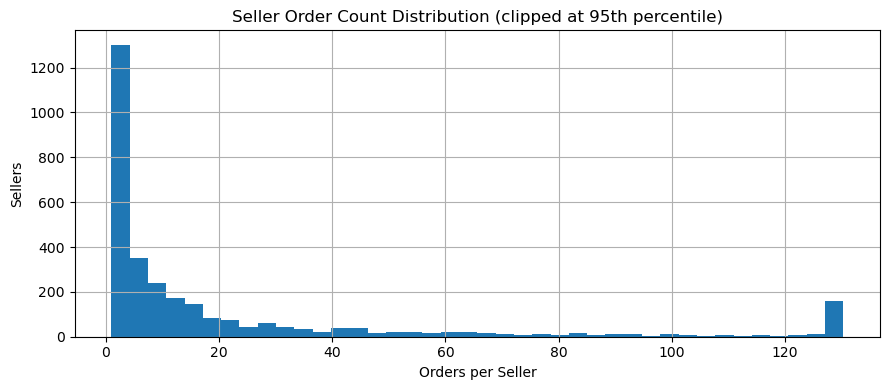

In [41]:
plt.figure(figsize=(9, 4))
seller_profile["orders"].clip(upper=seller_profile["orders"].quantile(.95)).hist(bins=40)
plt.title("Seller Order Count Distribution (clipped at 95th percentile)")
plt.xlabel("Orders per Seller")
plt.ylabel("Sellers")
plt.tight_layout()
plt.show()

### Merchandise-sales concentration

Sales shares show how much observed merchandise value is attributable to the largest sellers. Values are seller-attributable item prices; they exclude freight, payment totals, and any claim about profit or preventable losses.

The top 10 sellers account for 13.1% of merchandise value, the top 50 for 32.9%, and the top 100 for 45.1%. This concentration provides business context for seller-support prioritization without identifying which sellers provide poor customer experiences.

In [43]:
seller_sales_rank = seller_profile.sort_values("sales_value", ascending=False).copy()
seller_sales_rank["sales_share"] = (
    seller_sales_rank["sales_value"] / seller_sales_rank["sales_value"].sum()
)
seller_sales_rank["cumulative_sales_share"] = seller_sales_rank["sales_share"].cumsum()

concentration = pd.Series({
    "top_10_seller_sales_share": seller_sales_rank.head(10)["sales_share"].sum(),
    "top_50_seller_sales_share": seller_sales_rank.head(50)["sales_share"].sum(),
    "top_100_seller_sales_share": seller_sales_rank.head(100)["sales_share"].sum(),
})
concentration

top_10_seller_sales_share     0.131496
top_50_seller_sales_share     0.328888
top_100_seller_sales_share    0.450614
dtype: float64

## Placement-time Order Characteristics

Order value, shipping cost share, delivery promises, and seller geography describe information assumed available at placement. The summaries below compare low-review rates across existing feature groups. Category, listing metadata, and exported delivery promises retain the documented checkout-snapshot assumptions; fulfillment, payment, and review outcomes are excluded from predictive inputs.

In [45]:
order_eda = (
    olist_df.groupby("order_id")
    .agg(
        order_purchase_timestamp=("order_purchase_timestamp", "first"),
        customer_state=("customer_state", "first"),
        order_estimated_delivery_date=(
            "order_estimated_delivery_date",
            "first",
        ),
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        item_count=("order_item_id", "count"),
        unique_products=("product_id", "nunique"),
        last_review_score=("last_review_score", "first"),
    )
    .reset_index()
)

order_eda["low_review"] = np.where(
    order_eda["last_review_score"].isna(),
    np.nan,
    (order_eda["last_review_score"] <= 2).astype(int),
)

order_eda["freight_share"] = (
    order_eda["freight_value"]
    / (
        order_eda["merchandise_value"]
        + order_eda["freight_value"]
    )
)

order_eda["promised_delivery_days"] = (
    order_eda["order_estimated_delivery_date"]
    - order_eda["order_purchase_timestamp"]
).dt.total_seconds() / 86400

cross_state = (
    olist_df["seller_state"].ne(olist_df["customer_state"])
    .where(olist_df["seller_state"].notna() & olist_df["customer_state"].notna())
    .groupby(olist_df["order_id"]).max().rename("any_cross_state")
)
order_eda = order_eda.join(cross_state, on="order_id")

### Distributions of selected order characteristics

Four distributions describe the baseline orders, including those without reviews. Merchandise value uses a logarithmic horizontal scale to show its full range. Missing values are omitted separately for each plot; no orders or predictor values are changed. Item counts of five or more are grouped for display only. These plots describe the population rather than relationships with review outcomes.

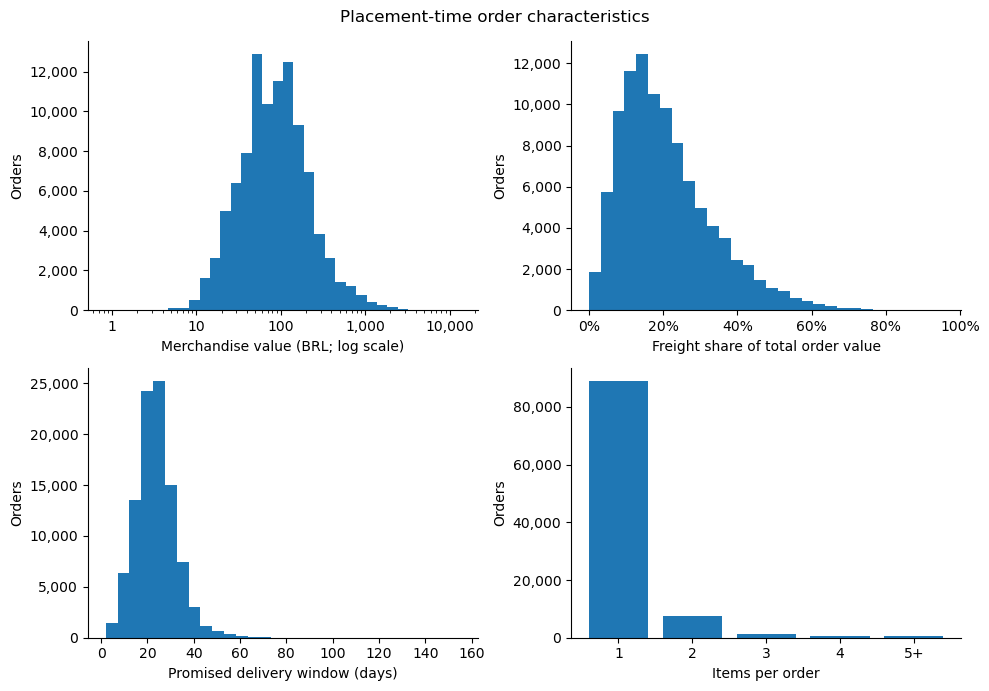

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
value_ax, freight_ax, promise_ax, items_ax = axes.flat
number_format = plt.FuncFormatter(lambda x, _: f"{x:,.0f}")

# Log-spaced bins retain the full merchandise-value range.
values = order_eda["merchandise_value"].dropna()
value_ax.hist(values, bins=np.geomspace(values.min(), values.max(), 35))
value_ax.set(
    xscale="log",
    xlabel="Merchandise value (BRL; log scale)",
)
value_ax.xaxis.set_major_formatter(number_format)

freight_ax.hist(order_eda["freight_share"].dropna(), bins=30)
freight_ax.set_xlabel("Freight share of total order value")
freight_ax.xaxis.set_major_formatter(PercentFormatter(1))

promise_ax.hist(order_eda["promised_delivery_days"].dropna(), bins=30)
promise_ax.set_xlabel("Promised delivery window (days)")

# Combine orders with five or more items for display.
item_counts = order_eda["item_count"].clip(upper=5).value_counts().sort_index()
items_ax.bar(item_counts.index, item_counts.values)
items_ax.set_xticks([1, 2, 3, 4, 5], ["1", "2", "3", "4", "5+"])
items_ax.set_xlabel("Items per order")

for ax in axes.flat:
    ax.set_ylabel("Orders")
    ax.yaxis.set_major_formatter(number_format)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Placement-time order characteristics")
plt.tight_layout()
plt.show()

In [48]:
features = [
    "merchandise_value",
    "freight_share",
    "promised_delivery_days",
    "item_count",
]

feature_labels = {
    "merchandise_value": "Merchandise value (BRL)",
    "freight_share": "Freight share",
    "promised_delivery_days": "Promised delivery window (days)",
    "item_count": "Item count",
}
feature_tables = {}
for feature in features:
    temp = order_eda.dropna(
        subset=[feature, "low_review"]
    ).copy()

    temp["quartile"] = pd.qcut(
        temp[feature],
        q=4,
        duplicates="drop",
    )

    result = (
        temp.groupby(
            "quartile",
            observed=True,
        )
        .agg(
            orders=("order_id", "count"),
            low_review_rate=("low_review", "mean"),
        )
    )

    feature_tables[feature] = result

feature_summary = pd.concat(feature_tables, names=["Feature", "Observed interval"])
feature_summary.index = feature_summary.index.set_levels(
    feature_summary.index.levels[0].map(feature_labels), level=0
)
display(feature_summary.rename(columns={
    "orders": "Reviewed orders", "low_review_rate": "Low-review rate",
}).style.format({"Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}"}))

Low-review prevalence increases from 12.2% in the lowest merchandise-value group to 17.2% in the highest. Longer promised delivery windows also have higher low-review prevalence, while differences across freight-share groups are modest. These are unadjusted associations and do not establish effects of changing prices or delivery promises.

Item-count quantiles collapse into a single interval because many orders have the same count. That row reproduces overall prevalence and does not demonstrate a relationship between basket size and reviews. No alternative bins are introduced here.

In [50]:
cross_state_summary = order_eda.groupby("any_cross_state").agg(
    reviewed_orders=("low_review", "count"),
    low_review_rate=("low_review", "mean"),
)
display(cross_state_summary.rename(
    index={False: "All observed sellers in customer state", True: "Any cross-state seller"},
    columns={"reviewed_orders": "Reviewed orders", "low_review_rate": "Low-review rate"},
).rename_axis("Seller geography").style.format({
    "Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}",
}))

,Reviewed orders,Low-review rate
Seller geography,,
All observed sellers in customer state,"35,110",11.8%
Any cross-state seller,"62,807",15.5%


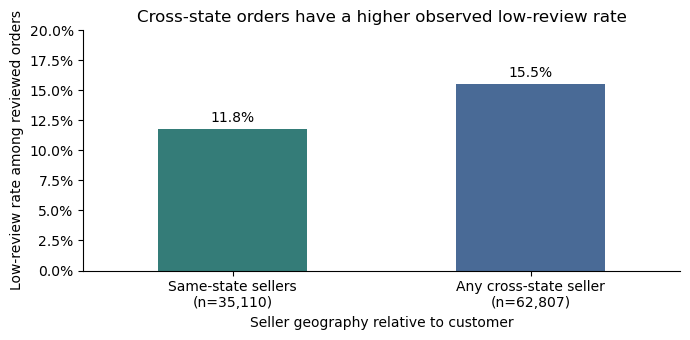

In [51]:
# Compare conditional rates, with reviewed-order counts visible.
ax = cross_state_summary["low_review_rate"].plot.bar(
    color=["#347C78", "#496A96"], figsize=(7, 3.5), rot=0,
)
ax.set_xticklabels([
    f"Same-state sellers\n(n={cross_state_summary.loc[False, 'reviewed_orders']:,.0f})",
    f"Any cross-state seller\n(n={cross_state_summary.loc[True, 'reviewed_orders']:,.0f})",
])
ax.bar_label(ax.containers[0], labels=[
    f"{rate:.1%}" for rate in cross_state_summary["low_review_rate"]
], padding=3)
ax.set_title("Cross-state orders have a higher observed low-review rate")
ax.set_xlabel("Seller geography relative to customer")
ax.set_ylabel("Low-review rate among reviewed orders")
ax.set_ylim(0, 0.2)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


Orders involving a cross-state seller have a 15.5% low-review rate, compared with 11.8% for orders whose observed sellers are in the customer's state. This difference identifies geographic context for further interpretation; it does not establish that shipping across states causes dissatisfaction. Missing seller or customer states remain unknown in the underlying indicator.

## Delivery Performance and Customer Experience

Actual customer delivery provides retrospective context rather than a placement-time predictor. An absent delivery timestamp indicates missing evidence, not confirmed non-delivery. Timing comparisons use calendar dates and, in the following summaries, require delivery at or after purchase and an observed promised date.

In [54]:
delivery = order_info.copy()
delivery["delivery_group"] = np.where(
    delivery["order_delivered_customer_date"].notna(),
    "Observed delivery", "No observed delivery",
)
delivery_coverage = delivery.groupby("delivery_group").agg(
    orders=("order_id", "size"), reviewed_orders=("reviewed", "sum"),
    low_reviews=("low_review", "sum"), low_review_rate=("low_review", "mean"),
)
display(delivery_coverage.rename(columns={
    "orders": "All orders", "reviewed_orders": "Reviewed orders",
    "low_reviews": "Low reviews", "low_review_rate": "Low-review rate",
}).rename_axis("Delivery evidence").style.format({
    "All orders": "{:,.0f}", "Reviewed orders": "{:,.0f}",
    "Low reviews": "{:,.0f}", "Low-review rate": "{:.1%}",
}))

,All orders,Reviewed orders,Low reviews,Low-review rate
Delivery evidence,,,,
No observed delivery,"2,190","2,087","1,617",77.5%
Observed delivery,"96,476","95,830","12,276",12.8%


In [55]:
valid = delivery["order_delivered_customer_date"].ge(
    delivery["order_purchase_timestamp"]
) & delivery["order_estimated_delivery_date"].notna()
days = (
    delivery["order_delivered_customer_date"].dt.normalize()
    - delivery["order_estimated_delivery_date"].dt.normalize()
).dt.days.where(valid)
delivery["timing_band"] = pd.cut(
    days, bins=[-np.inf, -7, -1, 0, 3, 7, 14, np.inf],
    labels=["7+ days early", "1–6 days early", "On promised date",
            "1–3 days late", "4–7 days late", "8–14 days late", "15+ days late"],
)
delivery["late"] = np.where(valid, days.gt(0), np.nan)
timing_summary = delivery.groupby("late").agg(
    reviewed_orders=("low_review", "count"),
    low_review_rate=("low_review", "mean"),
    low_reviews=("low_review", "sum"),
)
display(timing_summary.rename(
    index={0.0: "Early/on-time", 1.0: "Late"},
    columns={"reviewed_orders": "Reviewed orders", "low_reviews": "Low reviews",
             "low_review_rate": "Low-review rate"},
).rename_axis("Calendar-date delivery timing").style.format({
    "Reviewed orders": "{:,.0f}", "Low reviews": "{:,.0f}",
    "Low-review rate": "{:.1%}",
}))

,Reviewed orders,Low-review rate,Low reviews
Calendar-date delivery timing,,,
Early/on-time,"89,448",9.3%,"8,293"
Late,"6,382",62.4%,"3,983"


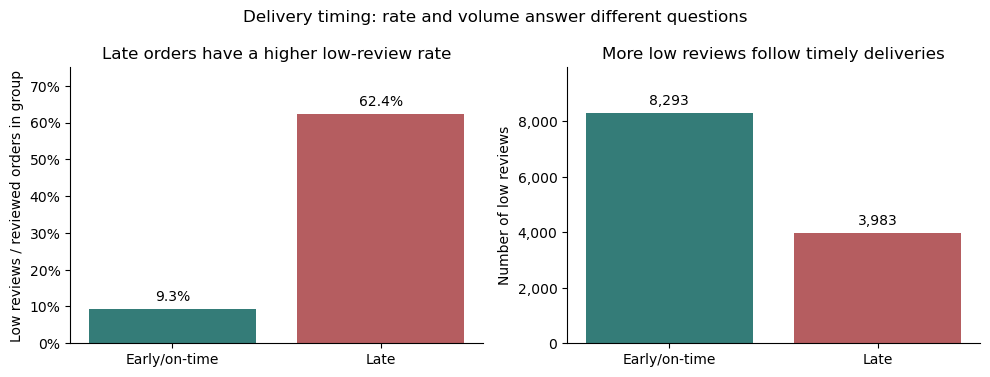

In [56]:
delivery_labels = ["Early/on-time", "Late"]
delivery_colors = ["#347C78", "#B55D60"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

rate_bars = axes[0].bar(
    delivery_labels, timing_summary["low_review_rate"], color=delivery_colors
)
axes[0].bar_label(rate_bars, labels=[
    f"{rate:.1%}" for rate in timing_summary["low_review_rate"]
], padding=4)
axes[0].set_title("Late orders have a higher low-review rate")
axes[0].set_ylabel("Low reviews / reviewed orders in group")
axes[0].set_ylim(0, 0.75)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))

count_bars = axes[1].bar(
    delivery_labels, timing_summary["low_reviews"], color=delivery_colors
)
axes[1].bar_label(count_bars, labels=[
    f"{count:,.0f}" for count in timing_summary["low_reviews"]
], padding=4)
axes[1].set_title("More low reviews follow timely deliveries")
axes[1].set_ylabel("Number of low reviews")
axes[1].set_ylim(0, timing_summary["low_reviews"].max() * 1.2)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:,.0f}"))
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Delivery timing: rate and volume answer different questions", fontsize=12)
plt.tight_layout()
plt.show()

### Calendar-date Delivery and Review Summary

Each order is counted once using the established latest answered review: 1–2 stars is low, and 3–5 stars is other. Delivery is late only when the actual calendar date is after the estimated calendar date; delivery on the promised date is on time regardless of hour. Overall low-review prevalence includes all reviewed orders. Delivery shares and row percentages use only reviewed orders with both dates; low-review case shares use only low-reviewed orders with both dates. Orders without an actual delivery date cannot be classified and are excluded from delivery comparisons, not from overall review prevalence. Missing estimated dates are also excluded. This summary adds the explicit denominators and contingency table without changing the existing delivery analyses.


In [ ]:
calendar_reviewed = order_info.loc[order_info["reviewed"]]
calendar_known = calendar_reviewed.dropna(subset=[
    "order_delivered_customer_date", "order_estimated_delivery_date",
])
calendar_status = np.where(
    calendar_known["order_delivered_customer_date"].dt.normalize()
    > calendar_known["order_estimated_delivery_date"].dt.normalize(),
    "Late", "On time or early",
)
calendar_review_group = np.where(
    calendar_known["last_review_score"].le(2), "Low review", "Other review"
)
calendar_summary = pd.crosstab(calendar_status, calendar_review_group).reindex(
    index=["On time or early", "Late"], columns=["Low review", "Other review"],
    fill_value=0,
)
calendar_summary.loc["Total"] = calendar_summary.sum()
calendar_summary["Total orders"] = calendar_summary.sum(axis=1)
calendar_summary["Reviewed-order share"] = (
    calendar_summary["Total orders"] / len(calendar_known)
)
calendar_summary["Low review row %"] = (
    calendar_summary["Low review"] / calendar_summary["Total orders"]
)
calendar_summary["Other review row %"] = (
    calendar_summary["Other review"] / calendar_summary["Total orders"]
)
calendar_summary["Share of low-review cases"] = (
    calendar_summary["Low review"] / calendar_summary.loc["Total", "Low review"]
)
print(
    f"All reviewed orders: {len(calendar_reviewed):,}; low reviews: "
    f"{int(calendar_reviewed['low_review'].sum()):,} "
    f"({calendar_reviewed['low_review'].mean():.1%})."
)
print(
    f"Delivery comparison: {len(calendar_known):,} reviewed orders; "
    f"{len(calendar_reviewed) - len(calendar_known):,} excluded for missing dates "
    f"(actual: {calendar_reviewed['order_delivered_customer_date'].isna().sum():,}; "
    f"estimated: {calendar_reviewed['order_estimated_delivery_date'].isna().sum():,})."
)
display(calendar_summary.rename_axis("Delivery status").style.format({
    "Low review": "{:,.0f}", "Other review": "{:,.0f}",
    "Total orders": "{:,.0f}", "Reviewed-order share": "{:.1%}",
    "Low review row %": "{:.1%}", "Other review row %": "{:.1%}",
    "Share of low-review cases": "{:.1%}",
}))


All reviewed orders: 97,917; low reviews: 13,893 (14.2%).


Delivery comparison: 95,830 reviewed orders; 2,087 excluded for missing dates (actual: 2,087; estimated: 0).


col_0,Low review,Other review,Total orders,Reviewed-order share,Low review row %,Other review row %,Share of low-review cases
row_0,,,,,,,
On time or early,"8,293","81,155","89,448",93.3%,9.3%,90.7%,67.6%
Late,"3,983","2,399","6,382",6.7%,62.4%,37.6%,32.4%
Total,"12,276","83,554","95,830",100.0%,12.8%,87.2%,100.0%


Late deliveries have a 62.4% low-review rate, compared with 9.3% for early/on-time deliveries. However, timely deliveries are much more common: among orders with valid observed timing, 8,293 low reviews occur after timely delivery versus 3,983 after late delivery. Lateness is therefore a strong warning signal, but it does not account for most observed low reviews in this timing population.

In [58]:
band_rates = delivery.groupby("timing_band", observed=False).agg(
    reviewed_orders=("low_review", "count"),
    low_review_rate=("low_review", "mean"),
)
display(band_rates.rename(columns={
    "reviewed_orders": "Reviewed orders", "low_review_rate": "Low-review rate",
}).rename_axis("Delivery timing").style.format({
    "Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}",
}))

,Reviewed orders,Low-review rate
Delivery timing,,
7+ days early,"75,749",9.0%
1–6 days early,"12,419",10.6%
On promised date,"1,280",12.4%
1–3 days late,"1,852",32.1%
4–7 days late,"1,748",67.7%
8–14 days late,"1,447",80.1%
15+ days late,"1,335",78.4%


### Review Ratings by Delivery-delay Severity

Low (1–2), neutral (3), and high (4–5) ratings distinguish different experiences among delayed orders. Percentages below use reviewed orders within each lateness band. This breakdown retains the original calendar-date lateness definition without adding the preceding summaries' valid-chronology restriction.

In [60]:
# Calculate delivery delays in calendar days.
late_df = eda_reviewed_orders.copy()

late_df["delivery_date"] = late_df["order_id"].map(
    olist_df.groupby("order_id")["order_delivered_customer_date"].first()
)

late_df["days_late"] = (
    late_df["delivery_date"].dt.normalize()
    - late_df["order_estimated_delivery_date"].dt.normalize()
).dt.days

# Restrict to reviewed orders delivered after their promised date.
late_df = late_df.loc[late_df["days_late"] > 0].copy()

late_df["lateness_band"] = pd.cut(
    late_df["days_late"],
    bins=[0, 3, 7, 14, np.inf],
    labels=["1–3 days", "4–7 days", "8–14 days", "15+ days"],
)

late_df["review_group"] = pd.cut(
    late_df["last_review_score"],
    bins=[0, 2, 3, 5],
    labels=["Low (1–2)", "Neutral (3)", "High (4–5)"],
)

late_review_table = pd.crosstab(
    late_df["lateness_band"],
    late_df["review_group"],
    normalize="index",
)

late_review_table["orders"] = (
    late_df["lateness_band"].value_counts().sort_index()
)

display(late_review_table.rename(columns={"orders": "Reviewed orders"})
    .rename_axis("Delay beyond promised date").style.format({
        "Low (1–2)": "{:.1%}", "Neutral (3)": "{:.1%}",
        "High (4–5)": "{:.1%}", "Reviewed orders": "{:,.0f}",
    }))

review_group,Low (1–2),Neutral (3),High (4–5),Reviewed orders
Delay beyond promised date,,,,
1–3 days,32.1%,14.7%,53.2%,"1,852"
4–7 days,67.7%,9.8%,22.5%,"1,748"
8–14 days,80.1%,8.9%,11.0%,"1,447"
15+ days,78.4%,9.1%,12.5%,"1,335"


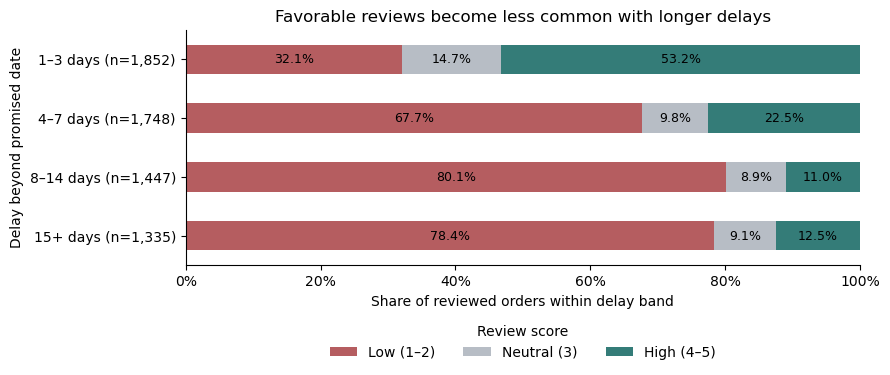

In [61]:
review_composition = late_review_table.drop(columns="orders")
ax = review_composition.plot.barh(
    stacked=True, color=["#B55D60", "#B7BDC5", "#347C78"], figsize=(9, 4)
)
ax.set_yticklabels([
    f"{band} (n={orders:,.0f})"
    for band, orders in late_review_table["orders"].items()
])
ax.invert_yaxis()
for bars in ax.containers:
    ax.bar_label(bars, labels=[f"{bar.get_width():.1%}" for bar in bars],
                 label_type="center", fontsize=9)
ax.set_title("Favorable reviews become less common with longer delays")
ax.set_xlabel("Share of reviewed orders within delay band")
ax.set_ylabel("Delay beyond promised date")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(title="Review score", loc="upper center", bbox_to_anchor=(0.5, -0.20),
          ncol=3, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

High ratings account for 53.2% of reviews when delivery is 1–3 days late, compared with 22.5% when it is 4–7 days late. Low ratings are more common in the longer-delay groups. The relationship is not strictly increasing across every band, and these associations do not establish causation. Meeting a delivery promise does not guarantee satisfaction, while missing it does not guarantee dissatisfaction.

## Seller Shipping-deadline Context

The shipping-deadline indicator compares order-level carrier handoff with the earliest item deadline. It is an order-context proxy and cannot identify which seller caused a delay. Joint results with customer-delivery lateness help distinguish this association from eventual delivery performance.

In [64]:
limits = olist_df.assign(
    shipping_limit_date=pd.to_datetime(olist_df["shipping_limit_date"])
).groupby("order_id")["shipping_limit_date"].min()
delivery = delivery.join(limits.rename("first_shipping_limit"), on="order_id")
valid_handoff = delivery["order_delivered_carrier_date"].ge(
    delivery["order_purchase_timestamp"]
) & delivery["first_shipping_limit"].notna()
delivery["any_deadline_miss"] = np.where(
    valid_handoff,
    delivery["order_delivered_carrier_date"].gt(delivery["first_shipping_limit"]),
    np.nan,
)
deadline_summary = delivery.groupby("any_deadline_miss").agg(
    reviewed_orders=("low_review", "count"), low_review_rate=("low_review", "mean"),
)
deadline_timing_summary = delivery.groupby(["any_deadline_miss", "late"]).agg(
    reviewed_orders=("low_review", "count"), low_review_rate=("low_review", "mean"),
)
display(deadline_summary.rename(
    index={0.0: "No observed miss", 1.0: "Observed miss"},
    columns={"reviewed_orders": "Reviewed orders", "low_review_rate": "Low-review rate"},
).rename_axis("Shipping-deadline proxy").style.format({
    "Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}",
}))
display(deadline_timing_summary.rename(
    index={0.0: "No", 1.0: "Yes"}, level=0,
).rename(index={0.0: "Early/on-time", 1.0: "Late"}, level=1).rename(
    columns={"reviewed_orders": "Reviewed orders", "low_review_rate": "Low-review rate"},
).rename_axis(["Deadline miss", "Customer delivery"]).style.format({
    "Reviewed orders": "{:,.0f}", "Low-review rate": "{:.1%}",
}))

,Reviewed orders,Low-review rate
Shipping-deadline proxy,,
No observed miss,"88,011",12.4%
Observed miss,"8,750",24.4%


Orders with an observed deadline miss have a 24.4% low-review rate, compared with 12.4% without an observed miss. Within late deliveries, the rates are much closer (63.2% versus 62.1%). Among timely deliveries, a difference remains (13.7% versus 8.9%). These comparisons qualify the unconditional association without establishing a causal pathway or seller responsibility.

## Findings and Implications for Modeling

| Finding | Implication for the project |
|---|---|
| Review outcomes are imbalanced, with 14.2% low reviews | Overall prevalence provides a baseline for evaluating risk concentration. |
| Historical prevalence changes across periods | Chronological evaluation complements the random historical benchmark; calendar patterns are not assumed to recur. |
| Repeat purchasing is uncommon in the observed history | Order-level customer-experience risk is the project's focus. |
| Order value, promised windows, and geography show descriptive associations | Placement-time characteristics provide a basis for modeling; their effects are not established by EDA. |
| Late delivery is strongly associated with low reviews, but most timing-observable low reviews follow timely delivery | Placement-time risk scoring can complement fulfillment monitoring rather than duplicate it. |
| Favorable reviews occur even after delays | Delivery performance and customer experience are related but not equivalent. |

### Scope and Limitations

Review-based comparisons are conditional on customers leaving an observed review; missing reviews are not treated as favorable outcomes. The baseline excludes orders without items. Short historical coverage, sparse months, repeated customers, and shared reviews limit generalization and independence. Missing delivery timestamps do not establish non-delivery, and seller-deadline indicators are proxies rather than seller-specific evidence.

Listing metadata and delivery promises retain the documented assumptions about availability at checkout. EDA associations do not establish causal effects or predict the benefit of an intervention. Fulfillment outcomes remain outside the placement-time feature set, and zero physical weights remain missing for modeling imputation.

Seller depth and sales concentration provide context for the secondary seller-support use case. Category-value summaries describe marketplace composition rather than customer-experience risk. Seller review and delivery summaries remain provisional until their flagged definitions are reviewed.